# Exploratory Data Analysis (EDA) - Carboplatin Sensing

Acest notebook realizeaza analiza exploratorie a datelor electrochimice generate pentru cuantificarea carboplatinei.
Se verifica distributia concentratiilor si comportamentul fizic al voltamogramelor (relatia Randles-Sevcik).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

df = pd.read_csv('../data/dataset_carboplatin_150_reale.csv')
df.head()

,sample_id,concentration_uM,V_0.200,V_0.205,V_0.210,V_0.215,V_0.220,V_0.225,V_0.230,V_0.235,...,V_1.355,V_1.360,V_1.365,V_1.370,V_1.375,V_1.380,V_1.385,V_1.390,V_1.395,V_1.400
0,sample_1,514.072869,-2.423639,1.414480,1.390781,3.392560,-0.705369,-0.478110,-0.518483,-1.363686,...,127.959709,137.570403,136.137633,134.877239,133.473230,131.336706,132.457800,134.048977,129.646355,130.129714
1,sample_2,118.356954,-0.894907,0.438165,0.674920,-0.555530,-0.013445,-0.079712,-0.168917,1.312073,...,29.312941,31.055379,31.223509,30.078432,30.577569,30.417170,32.090424,30.905867,30.151658,29.651294
2,sample_3,725.342977,-2.303059,-2.537224,0.235963,0.865649,-2.775144,-1.153316,-1.479426,0.200003,...,185.141744,184.012581,190.243716,193.241889,187.747249,182.948692,183.707175,180.482585,185.629990,179.218596
3,sample_4,754.158900,2.853735,4.811208,2.785955,2.070455,4.988578,7.737671,5.348195,-5.532341,...,192.270498,198.163986,190.010506,199.553994,192.461487,187.104380,193.109688,189.992557,195.854620,190.102070
4,sample_5,428.298758,-0.192482,0.425233,0.169676,-0.889849,6.092008,-0.334226,3.057346,-1.507084,...,108.731461,108.787427,111.033635,111.024422,107.856501,111.146362,108.163632,113.370631,107.577858,109.913705


## 1. Analiza Statistica a Concentratiilor

Vizualizam principalele metrici statistice si distributia variabilei tinta `concentration_uM` pentru a verifica absenta outlierilor si uniformitatea esantionarii.

Statistici descrietiive pentru concentratie (uM):
count     150.000000
mean      667.202441
std       378.387205
min        48.062403
25%       379.403595
50%       623.972896
75%       998.390416
max      1334.980597
Name: concentration_uM, dtype: float64


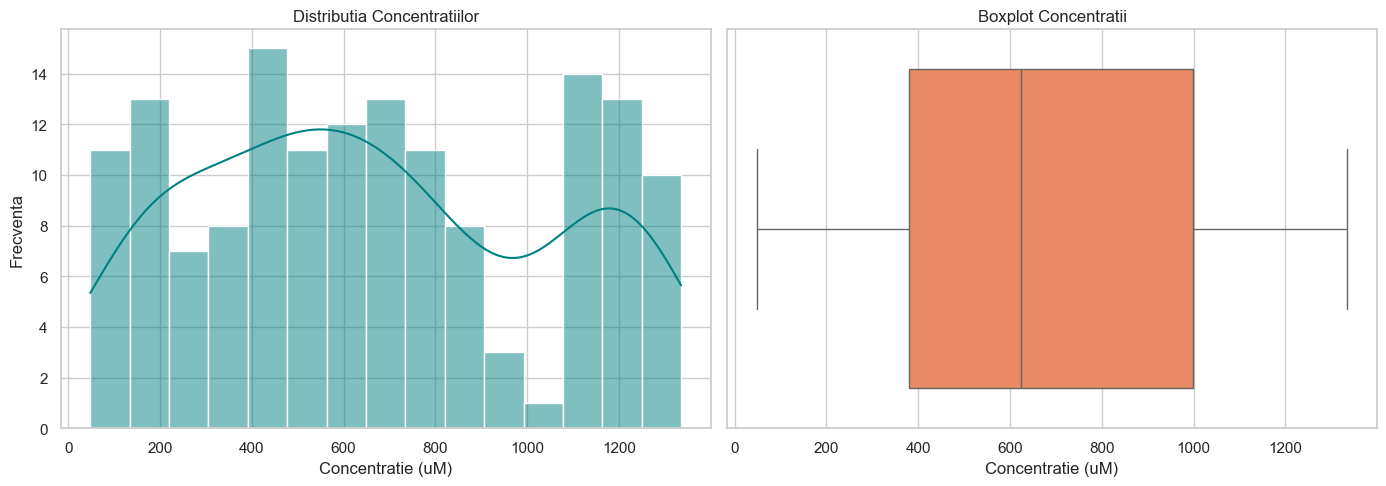

In [4]:
print("Statistici descrietiive pentru concentratie (uM):")
print(df['concentration_uM'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['concentration_uM'], kde=True, ax=axes[0], color='teal', bins=15)
axes[0].set_title('Distributia Concentratiilor')
axes[0].set_xlabel('Concentratie (uM)')
axes[0].set_ylabel('Frecventa')

sns.boxplot(x=df['concentration_uM'], ax=axes[1], color='coral')
axes[1].set_title('Boxplot Concentratii')
axes[1].set_xlabel('Concentratie (uM)')

plt.tight_layout()
plt.show()

## 2. Vizualizarea Voltamogramelor (Semnalul Electrochimic)

Generam graficul cu semnalele voltametrice $I(V)$ pentru primele probe din setul de date. Fiecare curba este colorata in functie de concentratia corespunzatoare.

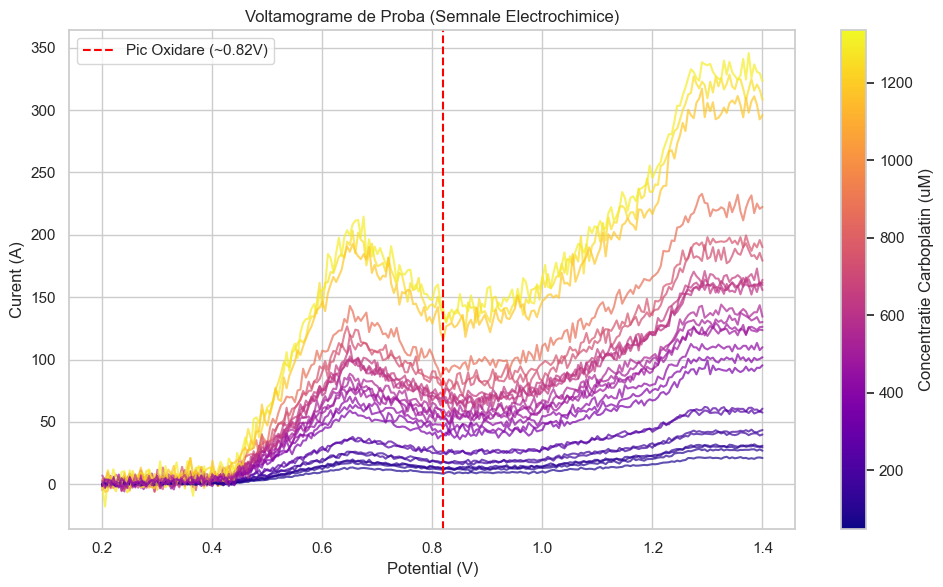

In [6]:
potential_cols = [c for c in df.columns if c.startswith('V_')]
potentials = [float(c.split('_')[1]) for c in potential_cols]

plt.figure(figsize=(10, 6))

cmap = plt.cm.plasma
norm = plt.Normalize(df['concentration_uM'].min(), df['concentration_uM'].max())

for i in range(25):
    row = df.iloc[i]
    currents = row[potential_cols].values
    conc = row['concentration_uM']
    plt.plot(potentials, currents, color=cmap(norm(conc)), alpha=0.7)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label('Concentratie Carboplatin (uM)')

plt.title('Voltamograme de Proba (Semnale Electrochimice)')
plt.xlabel('Potential (V)')
plt.ylabel('Curent (A)')
plt.axvline(x=0.820, color='red', linestyle='--', label='Pic Oxidare (~0.82V)')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Verificarea Relatiei Liniare de Pic (Randles-Sevcik)

Analizam proportionalitatea dintre intensitatea curentului la potentialul de oxidare ($V \approx 0.820\text{ V}$) si concentratia de carboplatin. Aceasta proprietate fizica constituie baza teoretica pentru penalizarea din modelul PINN.

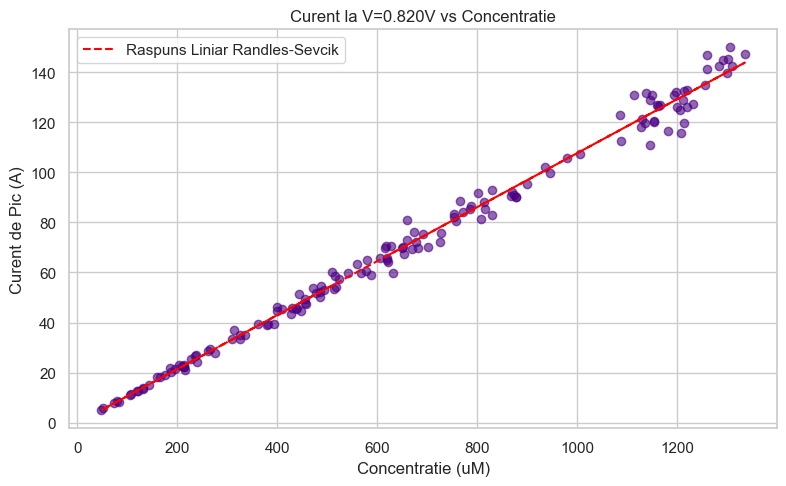

In [7]:
peak_col = min(potential_cols, key=lambda c: abs(float(c.split('_')[1]) - 0.820))
peak_potential = float(peak_col.split('_')[1])

plt.figure(figsize=(8, 5))
plt.scatter(df['concentration_uM'], df[peak_col], alpha=0.6, color='indigo')

m, b = np.polyfit(df['concentration_uM'], df[peak_col], 1)
plt.plot(df['concentration_uM'], m*df['concentration_uM'] + b, color='red', linestyle='--', label='Raspuns Liniar Randles-Sevcik')

plt.title(f'Curent la V={peak_potential:.3f}V vs Concentratie')
plt.xlabel('Concentratie (uM)')
plt.ylabel('Curent de Pic (A)')
plt.legend()
plt.tight_layout()
plt.show()